### Practice Question 6-1

Let's continue our work on the breast cancer dataset. Build a Logistic Regression model on the dataset, generate a the confusion matrix, and print the **Accuracy**, **Precision**, **Recall**, and **F1-score**. If this were a cancer prediction model a hospital would use, which specific metric should they focus on the most, based on their priority of avoiding missed cancer diagnoses?

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

cancer = load_breast_cancer(as_frame=True)
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, test_size=0.2, stratify=cancer.target, random_state=42)

model = LogisticRegression(max_iter=10000, random_state=0)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(f'Accuracy:  {accuracy_score(y_test, y_pred):.3f}')
print(f'Precision: {precision_score(y_test, y_pred):.3f}')
print(f'Recall:    {recall_score(y_test, y_pred):.3f}')
print(f'F1:        {f1_score(y_test, y_pred):.3f}')

[[39  3]
 [ 1 71]]
Accuracy:  0.965
Precision: 0.959
Recall:    0.986
F1:        0.973


#### <Practice Question 6-2>

In real-world classification tasks—such as financial fraud detection, rare disease diagnosis, or defect prediction—target class distributions are often severely skewed (e.g., 95\% negative vs. 5\% positive). In these situations, standard **classification accuracy** becomes a highly deceptive metric, giving a false sense of high performance even when a model fails to identify the minority class entirely. In this exercise, you will empirically demonstrate the 'accuracy paradox' by comparing model behavior across two synthetic datasets: one heavily imbalanced and one balanced.

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Imbalanced dataset (95% Class 0, 5% Class 1)
X_imbal, y_imbal = make_classification(
    n_samples=2000,
    n_features=5,
    n_informative=2,
    n_redundant=0,
    weights=[0.95, 0.05],
    class_sep=0.01,
    flip_y=0.05,
    random_state=42
)

# Balanced dataset (50% Class 0, 50% Class 1)
X_bal, y_bal = make_classification(
    n_samples=2000,
    n_features=5,
    n_informative=2,
    n_redundant=0,
    weights=[0.50, 0.50],
    class_sep=0.5,
    random_state=42
)

(1) Perform an 80/20 train-test split (`test_size=0.2, random_state=0`) on both the balanced and imbalanced datasets. Next, initialize and train two separate Logistic Regression classifiers on their respective training sets.

In [ ]:
# (1)
# Split the two datasets into a 8:2 ratio
# WRITE ME
X_train_bal, X_test_bal, y_train_bal, y_test_bal = train_test_split(
    X_bal, y_bal, test_size=0.2, random_state=42
)
X_train_imbal, X_test_imbal, y_train_imbal, y_test_imbal = train_test_split(
    X_imbal, y_imbal, test_size=0.2, random_state=0
)

# Train a Logistic Regression model on the two datasets
# WRITE ME
model_bal = LogisticRegression(random_state=0, max_iter=10000)
model_bal.fit(X_train_bal, y_train_bal)
model_imbal = LogisticRegression(random_state=0, max_iter=10000)
model_imbal.fit(X_train_imbal, y_train_imbal)

LogisticRegression(max_iter=10000, random_state=0)

(2) For both trained models, generate class prediction labels and positive-class predicted probabilities on their respective test sets. Compute and print the accuracy alongside the ROC-AUC  score for both models.

In [ ]:
# (2)
# Generate predictions
# WRITE ME
y_pred_bal = model_bal.predict(X_test_bal)
y_pred_imbal = model_imbal.predict(X_test_imbal)
y_pred_proba_bal = model_bal.predict_proba(X_test_bal)[:,1]
y_pred_proba_imbal = model_imbal.predict_proba(X_test_imbal)[:,1]

# Calculate the metrics
# WRITE ME
acc_bal = accuracy_score(y_test_bal, y_pred_bal)
acc_imbal = accuracy_score(y_test_imbal, y_pred_imbal)
auc_bal = roc_auc_score(y_test_bal, y_pred_proba_bal)
auc_imbal = roc_auc_score(y_test_imbal, y_pred_proba_imbal)
print(f'Accuracy for balanced dataset: {acc_bal:.3f}')
print(f'Accuracy for imbalanced dataset: {acc_imbal:.3f}')
print(f'ROC-AUC for balanced dataset: {auc_bal:.3f}')
print(f'ROC-AUC for imbalanced dataset: {auc_imbal:.3f}')

Accuracy for balanced dataset: 0.765
Accuracy for imbalanced dataset: 0.930
ROC-AUC for balanced dataset: 0.817
ROC-AUC for imbalanced dataset: 0.491


(3) Compute the False Positive Rate (FPR) and True Positive Rate (TPR) across varying decision thresholds using roc_curve. Plot the ROC curves for both models on a single graph, along with a baseline dashed line representing a random classifier (AUC = 0.50).

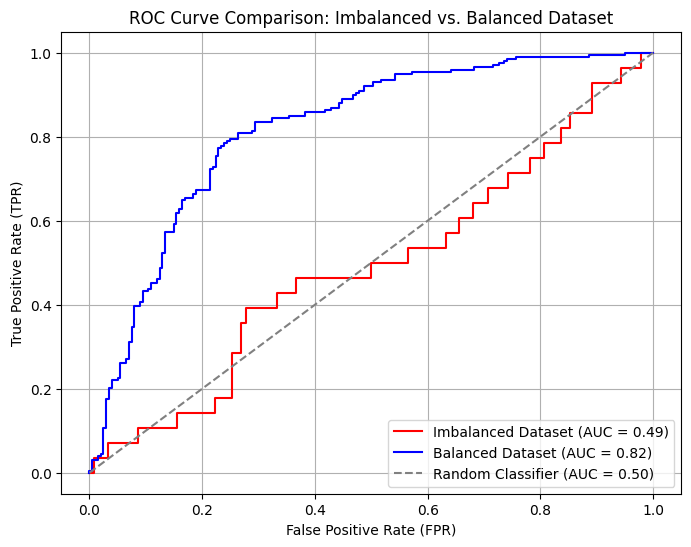

In [ ]:
# Calculate the fpr and tpr for the two datasets
fpr_bal, tpr_bal, thresholds_bal = roc_curve(y_test_bal, y_pred_proba_bal)
fpr_imbal, tpr_imbal, thresholds_imbal = roc_curve(y_test_imbal, y_pred_proba_imbal)

# Draw the ROC-AUC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr_imbal, tpr_imbal, color='red', label=f'Imbalanced Dataset (AUC = {auc_imbal:.2f})')
plt.plot(fpr_bal, tpr_bal, color='blue', label=f'Balanced Dataset (AUC = {auc_bal:.2f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Classifier (AUC = 0.50)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curve Comparison: Imbalanced vs. Balanced Dataset')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()



---
## 6.4 Comprehensive Question

### **Practice Project: Telemarketing Optimization & Workforce Planning**

1. Business Background & Problem Statement

*Global Trust Bank* is launching a targeted outreach campaign to increase term-deposit subscriptions. However, operational capacity is contrained by call-center staffing and outbound budget limits.

The strategy team requires two machine learning components to optimize this campaign:

*   Component A: A classification engine to target customers likely to subscribe.
*   Component B: A regression engine to estimate individual call durations, enabling accurate shift planning for call center representatives.

2. Operational & Financial Contraints

A naive model that predicts "No" for all customers will yield high raw accuracy due to class imbalance, but it will cripple campaign revenue. You must evaluate models using financial risk alginment:

*   Model predicts *Subscribe*, but customer declines: Wasted agent labor costs ($10 per call).

*   Model predicts *Will Not Subscribe*, so no call is made, but the customer would have accepted: Lost high-yield revenue opportunity ($100 per missed client).

Your task is to create a classification and a regression model that addresses everything mentioned above.

Run the two cells below to install the UCI repository tool and load your dataset.

In [1]:
!pip install ucimlrepo

In [2]:
import pandas as pd
import numpy as np
from ucimlrepo import fetch_ucirepo

# Fetch Bank Marketing dataset (UCI ID: 222)
bank_marketing = fetch_ucirepo(id=222)

df = bank_marketing.data.features.select_dtypes(include=['int64', 'float64']).copy()
df['target'] = (bank_marketing.data.targets['y'] == 'yes').astype(int)

df.head()

,age,balance,day_of_week,duration,campaign,pdays,previous,target
0,58,2143,5,261,1,-1,0,0
1,44,29,5,151,1,-1,0,0
2,33,2,5,76,1,-1,0,0
3,47,1506,5,92,1,-1,0,0
4,33,1,5,198,1,-1,0,0


For reference, here are the definition of the columns we are going to deal with:

* **age:** Age of the client
* **balance:** Average yearly balance in euros
* **day_of_week:** Last contact day of the week
* **duration:** Last contact duration in seconds
* **campaign:** Number of calls made to this client during the current campaign
* **pdays:** Days since the client was last contacted from a previous campaign (-1 means never contacted)
* **previous:** Number of calls made to this client before the current campaign

### Task 1

(1) Calculate the distribution of the target variable (`0` vs `1`).

In [3]:
print(df['target'].value_counts())

target
0    39922
1     5289
Name: count, dtype: int64


(2) Based on the financial breakdown (\$10 penalty vs $100 penalty), should the team prioritize **Precision** or **Recall**? Why would **Accuracy** not be a good metric in this case?

Answer: The team should prioritize **precision**, because a false negative (not calling a potential customer) is more damaging than a false positive (calling someone who will decline). Accuracy is not a good metric because we are dealing with an imbalanced dataset, and even if the model has high accuracy, we can not tell if it is meaningful. For example, we cannot tell if the model had high accuracy on both classes, or simply predicted `0` for every single customer.

### Task 2

Choose two classification algorithms (e.g. Logistic Regression and Decision Trees) and implement **5-fold Cross Validation**. Instead of using the default metric, use the metric you decided would be best in Task 1. Then identify which model consistently minimizes financial losses under k-fold validation.

Hint: Each feature has different scales, so make sure to address this before giving the model the data.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import precision_score
from sklearn.preprocessing import StandardScaler

# What should you do to the data before giving it to the models?
## WRITE ME
X = df.drop(columns=['target'])
y = df['target']
sc = StandardScaler()
X = sc.fit_transform(X)

# Create the two models you chose
## WRITE ME
lr = LogisticRegression(max_iter=10000)
dt = DecisionTreeClassifier()

# Conduct 5-fold cross validation on the models you created, and determine which model is the best fit for this task
## WRITE ME
for model in [lr,dt]:
  scores = cross_val_score(model, X, y, cv=5, scoring='precision')
  print(f'{model.__class__.__name__}: {scores.mean():.3f}')

LogisticRegression: 0.526
DecisionTreeClassifier: 0.272


### Task 3

When we are actually calling potential customers, we obviously do not know how long the call will take before we get a "Yes" or a "No". The Operations Teams need to forecast the `duration` column using the remaining numerical features (`age`,`balance`,etc.).

(1) Define a new regression target and feature set. Then perform a train/test split and scale the features.


In [6]:
from sklearn.model_selection import train_test_split
# Define new target and features
## WRITE ME
X = df[['age', 'balance', 'day_of_week', 'campaign', 'pdays', 'previous']]
y = df['duration']

# Split the data into training and testing data
## WRITE ME
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

(2) Train a Ridge or Lasso regression model and compute the Root Mean Squared Error. How would you explain this mean value to a person who does not have a technical background?

In [9]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
# Train model
model = Ridge()
model.fit(X_train, y_train)

# Compute the RMSE on the testing data you created in (1)
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f'RMSE: {rmse:.3f}')

RMSE: 259.298


Answer: The root mean squared error of the model we created was 259.298 seconds, which means that on average, this model is off by a little over 4 minutes. Condsidering how most of data has a `duration` of less than 500 seconds, this model is not performing very vell.